# Phase 4 – Product classification (Q1.3 PriceRunner)


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

## 4.1 EDA and data preprocessing

### A. EDA and preprocessing of the selected characteristics

In [2]:

price_runner = pd.read_csv("phase4-data/pricerunner_aggregate.csv", header=None, 
    names=["product_id", "product_title", "vendor_id", "cluster_id", "cluster_label", "category_id", "category_label"])

In [3]:
display(price_runner.shape)
display(price_runner.head())

(35311, 7)

,product_id,product_title,vendor_id,cluster_id,cluster_label,category_id,category_label
0,1,apple iphone 8 plus 64gb silver,1,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
1,2,apple iphone 8 plus 64 gb spacegrau,2,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
2,3,apple mq8n2b/a iphone 8 plus 64gb 5.5 12mp sim...,3,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
3,4,apple iphone 8 plus 64gb space grey,4,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones
4,5,apple iphone 8 plus gold 5.5 64gb 4g unlocked ...,5,1,Apple iPhone 8 Plus 64GB,2612,Mobile Phones


In [4]:
def categories_distribution():
    return price_runner.groupby("category_label").agg(rows=("product_title", "size"), products=("cluster_id", "nunique")).sort_values("rows", ascending=False).head(10)

display(categories_distribution())

,rows,products
category_label,,
Fridge Freezers,5501,1998
Mobile Phones,4081,1704
Washing Machines,4044,1277
CPUs,3862,1975
Fridges,3584,1373
TVs,3564,1280
Dishwashers,3424,1368
Digital Cameras,2697,713
Microwaves,2342,785


### Choice of the 5 classes

The task requires 5 classes, so we keep 5 of the 10 categories: 
- Mobile Phones
- Washing Machines
- CPUs
- TVs
- Digital Cameras

New shape: (18248, 7)


,rows,products
category_label,,
Mobile Phones,4081,1704
Washing Machines,4044,1277
CPUs,3862,1975
TVs,3564,1280
Digital Cameras,2697,713


<Axes: xlabel='category_label'>

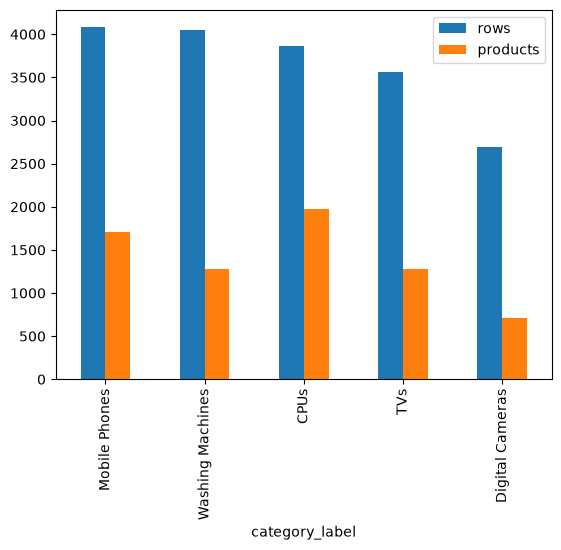

In [5]:
chosen_categories = ["Mobile Phones", "Washing Machines", "CPUs", "TVs", "Digital Cameras"]
price_runner = price_runner[price_runner.category_label.isin(chosen_categories)]

print(f"New shape: {price_runner.shape}")
distribution = categories_distribution()
display(distribution)
distribution.plot(kind="bar")

In [6]:
price_runner.info()
display(price_runner.describe())
display(price_runner.nunique())

print("Any nulls ?:", price_runner.isna().sum().sum() != 0)
print("Each product belongs to exactly one category:", price_runner.groupby("cluster_id")["category_label"].nunique().max() == 1)

<class 'pandas.DataFrame'>
Index: 18248 entries, 0 to 24013
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   product_id      18248 non-null  int64
 1   product_title   18248 non-null  str  
 2   vendor_id       18248 non-null  int64
 3   cluster_id      18248 non-null  int64
 4   cluster_label   18248 non-null  str  
 5   category_id     18248 non-null  int64
 6   category_label  18248 non-null  str  
dtypes: int64(4), str(3)
memory usage: 1.1 MB


,product_id,vendor_id,cluster_id,category_id
count,18248.000000,18248.000000,18248.000000,18248.000000
mean,16626.426074,75.180732,17581.446624,2615.537429
std,10656.095563,87.437572,18045.861359,2.837465
min,1.000000,1.000000,1.000000,2612.000000
25%,10531.750000,14.000000,4448.000000,2614.000000
50%,15305.000000,44.000000,6240.500000,2615.000000
75%,23245.250000,121.000000,39193.000000,2617.000000
max,34725.000000,361.000000,43261.000000,2620.000000


product_id        18248
product_title     15876
vendor_id           262
cluster_id         6949
cluster_label      6571
category_id           5
category_label        5
dtype: int64

Any nulls ?: False
Each product belongs to exactly one category: True


- No missing values.
- `product_title` has only 15,876 unique values in 18,248 rows meaning there are duplicate titles.

In [7]:
print("Duplicated rows:", price_runner.duplicated().sum())
print("Duplicated titles:", price_runner["product_title"].duplicated().sum())

dups = price_runner[price_runner.duplicated("product_title", keep=False)]
display(dups.sort_values("product_title").head(10))

Duplicated rows: 0
Duplicated titles: 2372


,product_id,product_title,vendor_id,cluster_id,cluster_label,category_id,category_label
20676,30898,10 kg washing machine with add wash,347,41929,Samsung WW10M86DQOO,2620,Washing Machines
20540,30754,10 kg washing machine with add wash,347,41915,Samsung WW10M86DQOA/EU,2620,Washing Machines
6438,12475,109.22 cm 43 1920 x 1080 lcd smart tv dvb t2/c...,18,4856,LG 49LJ594V,2614,TVs
6282,12313,109.22 cm 43 1920 x 1080 lcd smart tv dvb t2/c...,18,4802,LG 43LJ594V,2614,TVs
21085,31358,1200rpm washing machine 7kg load class a white,123,41984,Indesit IWC 71252 ECO,2620,Washing Machines
22628,33090,1200rpm washing machine 7kg load class a white,123,42302,Whirlpool FWL71253W UK,2620,Washing Machines
22469,32908,1200rpm washing machine 7kg load class a white,123,42255,Indesit BWD 71252 W UK.R,2620,Washing Machines
20594,30809,1200rpm washing machine 7kg load class a white,123,41920,Hotpoint WMAQF721P,2620,Washing Machines
23265,33948,1200rpm washing machine 9kg load class a black,123,42570,Beko WMB91243LB,2620,Washing Machines
23640,34345,1200rpm washing machine 9kg load class a black,123,42788,Beko WMB91242LB,2620,Washing Machines


There are no duplicate rows (each offer has its own `product_id`), but **2,372 titles are repeated**. 

In [8]:
categories_per_vendor = price_runner.groupby("vendor_id")["category_label"].nunique()

print("Number of vendors:", len(categories_per_vendor))

rows = []
for k in range(1, 6):
    vendors_k = categories_per_vendor[categories_per_vendor == k].index

    rows.append({
        "Amount of categories": k,
        "shops": (categories_per_vendor == k).sum(),
        "share_of_shops": round((categories_per_vendor == k).mean(), 3) * 100,
        "share_of_offers": round(price_runner["vendor_id"].isin(vendors_k).mean(), 3) * 100,
    })

display(pd.DataFrame(rows).set_index("Amount of categories"))

Number of vendors: 262


,shops,share_of_shops,share_of_offers
Amount of categories,,,
1,162,61.8,22.9
2,51,19.5,18.8
3,24,9.2,13.8
4,21,8.0,24.9
5,4,1.5,19.6


In [9]:
from sklearn.model_selection import StratifiedGroupKFold

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
y = price_runner["category_label"]

vendor_scores = []
baseline_scores = []

for train_idx, val_idx in cv.split(price_runner, y, groups=price_runner["cluster_id"]):
    train_part = price_runner.iloc[train_idx]
    val_part = price_runner.iloc[val_idx]

    most_common = train_part["category_label"].mode()[0]
    vendor_category = train_part.groupby("vendor_id")["category_label"].agg(lambda s: s.mode()[0])

    prediction = val_part["vendor_id"].map(vendor_category)

    vendor_scores.append((prediction == val_part["category_label"]).mean())
    baseline_scores.append((val_part["category_label"] == most_common).mean())

print("Baseline (most common class):", np.round(np.mean(baseline_scores), 3))
print("Vendor only, per fold:", np.round(vendor_scores, 3))
print("mean:", np.round(np.mean(vendor_scores), 3))

Baseline (most common class): 0.224
Vendor only, per fold: [0.694 0.692 0.699 0.697 0.687]
mean: 0.694


**Vendor as a possible feature.** 62 % of the shops sell only one of the 5 categories, but they list only 23 % of the
offers. Still, predicting each shop's most common category reaches **69.4 %** accuracy against **22.4 %** for always predicting the most common class.

The vendor is informative, but it is a nominal id with 262 values, a new shop cannot be encoded and the model could learn
shop shortcuts instead of reading the title. The **title stays the main feature**; `vendor_id` is left as a candidate
feature to be tested on top of the title in 4.2.

words                                                    \
                   count       mean       std  min   25%   50%   75%   max   
category_label                                                               
CPUs              3862.0  12.417141  3.819109  2.0  10.0  12.0  15.0  29.0   
Digital Cameras   2697.0   9.619577  4.677178  2.0   6.0   9.0  12.0  36.0   
Mobile Phones     4081.0   8.547415  5.605780  2.0   5.0   7.0  11.0  37.0   
TVs               3564.0  10.247475  4.481469  2.0   7.0  10.0  13.0  31.0   
Washing Machines  4044.0   7.819980  3.125891  2.0   6.0   8.0  10.0  22.0   

                   chars                                                       
                   count       mean        std   min   25%   50%   75%    max  
category_label                                                                 
CPUs              3862.0  67.031331  20.291652  11.0  55.0  65.0  76.0  190.0  
Digital Cameras   2697.0  50.083797  24.519863   6.0  34.0  44.0  61.0  180.0  
Mobile Phones     4081.0  46.203627  30.707163   5.0  26.0  40.0  57.0  200.0  
TVs               3564.0  54.704545  23.417287   6.0  40.0  53.0  65.0  195.0  
Washing Machines  4044.0  53.013600  18.836410  10.0  42.0  54.0  65.0  149.0

<Axes: xlabel='words', ylabel='category_label'>

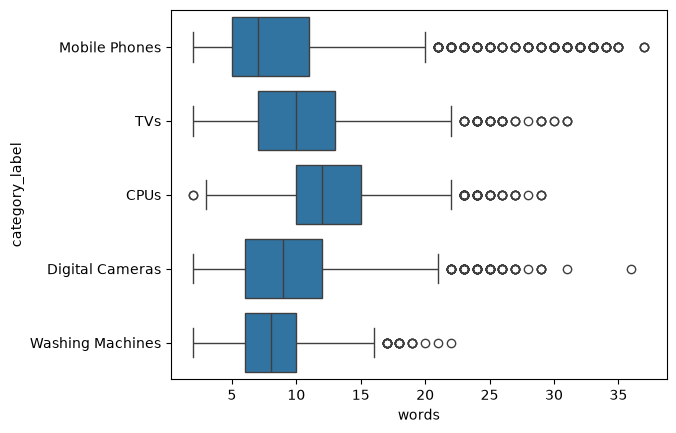

In [10]:
price_runner["words"] = price_runner["product_title"].str.split().str.len()
price_runner["chars"] = price_runner["product_title"].str.len()
display(price_runner.groupby("category_label")[["words", "chars"]].describe())

sns.boxplot(price_runner, x="words", y="category_label")

Shortest titles:


['lg q6', 'lg g5', 'lg g4', 'lg g2', 'lg k7']

Longest titles:


['ulefone armor2 ip68 rugged unlocked 4g cellphone smartphone mobilephone 5 inch fhd screen 6gb 64gb 8 core powerful helio p25 2.6ghz cpu super power savery 4700mah battery best pe 2.0 fast charge water',
 'vkworld s8 5.99inch fhd 2160 1080 18 9 android7.0 bezel less face id smartphone mtk6750t octa memory 4gb 64gb battery 5500mah back16mp 5mp dual camera and front 13mp fingerprint contains uk specificat',
 'vkworld t2 plus 4.2 inch dual screen flip phone android 7.0 3g ram 32g rom big battery 2000mah with big button physical keyboard smartphone aac speaker fm radio bluetooth dual sim 4g unlocked sim free',
 'ulefone power 2 smartphone cellphone mobilephone super powerful battery 6050mah 9v/2a quick charge 5.5 inch fhd screen android 7.0 mtk6750t octa core 1.5ghz 4gb ram 64gb rom camera 13mp 8mp 14 light f',
 'ulefone power 5 big battery 4g mobile 13000mah battery 6.0 fhd mt6763 octa core 64 bit 2.0ghz cpu android 8.1 6gb ram 64gb rom mobile dual sim business unlock phone 21mp 5mp dual

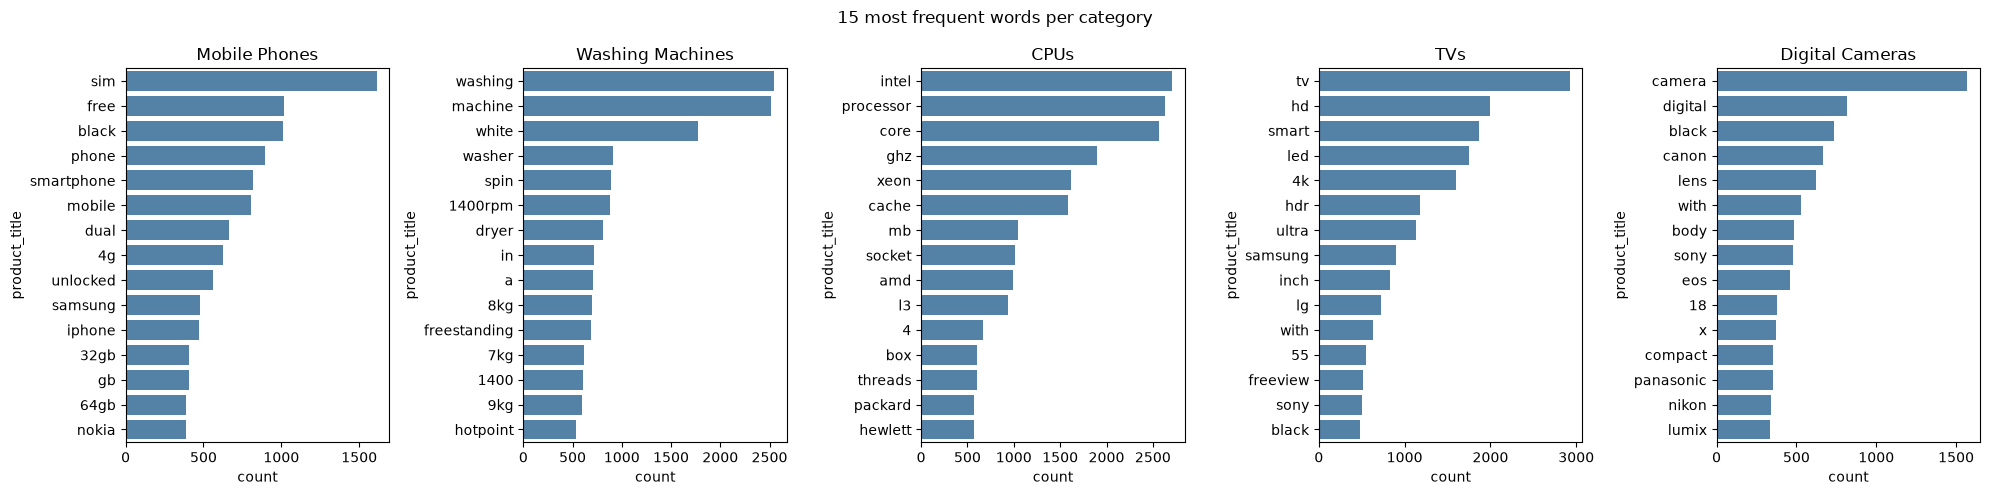

In [11]:
def plot_top(column: str):
    fig, axes = plt.subplots(1, 5, figsize=(20, 5))

    for ax, category in zip(axes, chosen_categories):
        titles = price_runner.loc[price_runner["category_label"] == category, column]
        top_words = titles.str.split().explode().value_counts().head(15)
        sns.barplot(x=top_words.values, y=top_words.index, ax=ax, color="steelblue")
        ax.set_title(category)
        ax.set_xlabel("count")

    fig.suptitle("15 most frequent words per category")
    plt.tight_layout()
    plt.show()

print("Shortest titles:")
display(price_runner.nsmallest(5, "chars")["product_title"].to_list())

print("Longest titles:")
display(price_runner.nlargest(5, "chars")["product_title"].to_list())

plot_top("product_title")

In [12]:
import re

all_text = "".join(price_runner["product_title"])

print("Special characters:", set(re.findall(r"[^a-z0-9 ]", all_text)))
print("Titles with uppercase:", price_runner["product_title"].str.contains("[A-Z]").sum())

def clean_title(title):
    title = title.lower()
    title = re.sub(r"\b(\d+(?:\.\d+)?)([a-z]+)\b", r"\1 \2", title) # space between value and units
    title = re.sub(r"[^a-z0-9.]+", " ", title) # special characters to spaces
    title = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", title) # keep dots only in numbers
    return " ".join(title.split())

price_runner["clean_title"] = price_runner["product_title"].map(clean_title)

display(price_runner.sample(5))

Special characters: {'/', '.'}
Titles with uppercase: 0


,product_id,product_title,vendor_id,cluster_id,cluster_label,category_id,category_label,words,chars,clean_title
4037,4048,nokia n95 mobile phone,48,1777,Nokia N95,2612,Mobile Phones,4,22,nokia n95 mobile phone
10178,16565,hp amd opteron dual core 2214 he 2.2ghz 1mb l2...,66,6712,HP AMD Opteron 2214 HE 2.2GHz Upgrade Tray,2615,CPUs,11,56,hp amd opteron dual core 2214 he 2.2 ghz 1 mb ...
9652,15980,intel xeon processor e5 2683 v3 35m cache 2.00...,45,6479,Intel Xeon E5-2683 v3 2GHz Tray,2615,CPUs,14,72,intel xeon processor e5 2683 v3 35 m cache 2.0...
4035,4046,nokia 6085 mobile phone,48,1775,Nokia 6085,2612,Mobile Phones,4,23,nokia 6085 mobile phone
3189,3199,bq aquaris v plus 32gb 3gb ram white/gold 13 9...,17,1002,Bq Aquaris V Plus 32GB Dual SIM,2612,Mobile Phones,19,94,bq aquaris v plus 32 gb 3 gb ram white gold 13...


The titles are already lowercase and contain only two special characters (`.` and `/`), so the cleaning is simple:
1. lowercase (for safety on new data),
2. split a number from its unit only if the whole token is number + unit
3. replace other characters (`/`) with a space and keep a dot only inside decimal numbers,
4. remove repeated spaces.

In [13]:
price_runner = price_runner.drop_duplicates("clean_title").reset_index(drop=True)
print("Shape after dropping duplicates:", price_runner.shape)

Shape after dropping duplicates: (15852, 10)


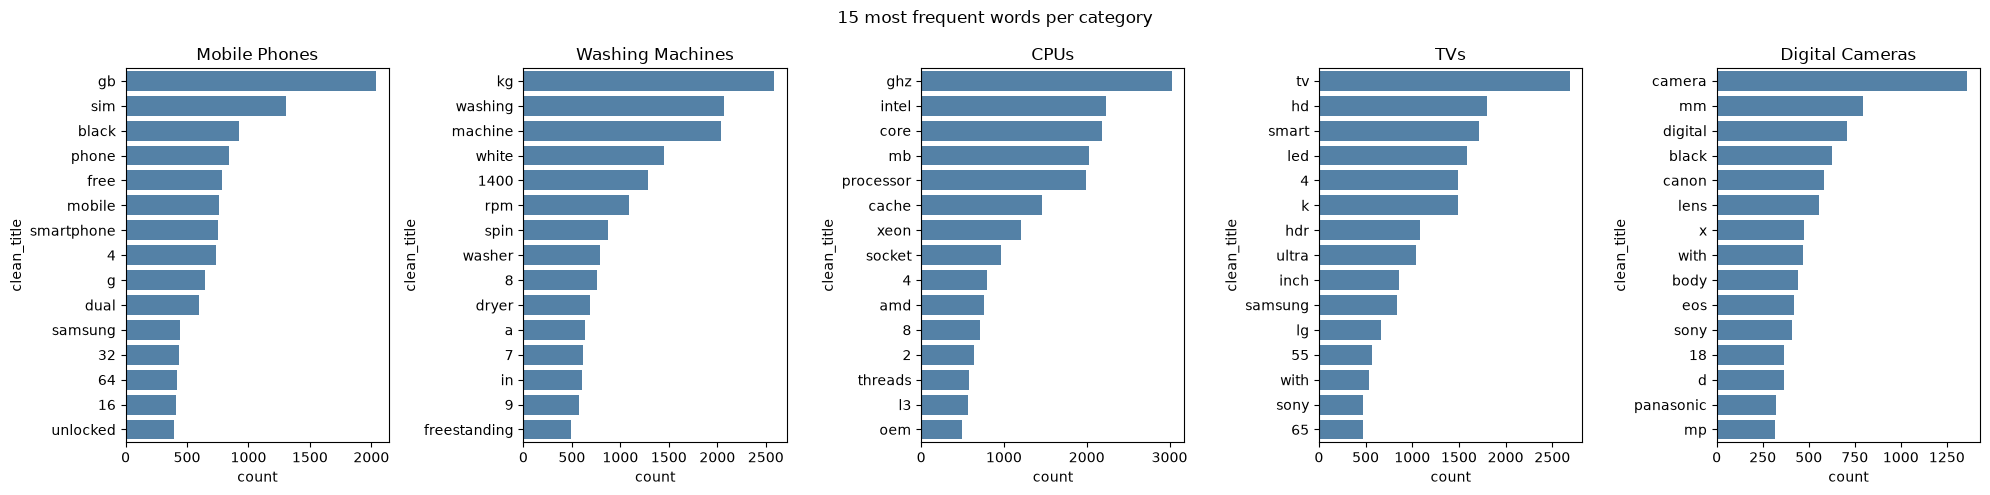

In [14]:
plot_top("clean_title")

After cleaning, units are among the most frequent words: *gb* (Mobile Phones), *kg* and *rpm* (Washing Machines),
*ghz* and *mb* (CPUs), *mm* (Digital Cameras). Instead of many rare tokens (*7kg, 8kg, 9kg*) the model gets one strong
shared feature per unit.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

def clean_titles(titles):
    return [clean_title(t) for t in titles]

train, test = train_test_split(
    price_runner,
    test_size=0.2,
    stratify=price_runner["category_label"],
    random_state=42,
)

preprocessing = Pipeline([
    ("clean", FunctionTransformer(clean_titles)),
    ("tfidf", TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
])

X_train = preprocessing.fit_transform(train["product_title"])
X_test = preprocessing.transform(test["product_title"])
y_train, y_test = train["category_label"], test["category_label"]
groups_train = train["cluster_id"]

print("X_train:", X_train.shape, "X_test:", X_test.shape)

X_train: (12681, 15303) X_test: (3171, 15303)


### Summary of preprocessing

1. Only the product title is used as a feature, other columns are identifiers or encode the target
   (`vendor_id` stays a candidate feature for 4.2).
2. Titles are cleaned (numbers separated from units, special characters removed) and duplicate titles are dropped.
3. The data is split 80/20 with stratification, so both sets keep the same class proportions.
4. Text cleaning and TF-IDF are combined in one sklearn `Pipeline`.

### B. Choice of ML methods for 4.2

**Character of the data:** one text feature – short titles (~ 8–12 words) turned into a sparse TF-IDF matrix with
15,303 features, of which each title uses only a few.

**Chosen methods:**
- **Multinomial Naive Bayes** - classic, very fast baseline for text classification.
- **Logistic Regression** - standard linear model for TF-IDF, it is fast on sparse data and its weights show which words
  decide each class.
- **LinearSVC** - linear model that maximises the margin between classes; works well in high-dimensional text data.

**Evaluation:** accuracy and macro precision, recall and F1, confusion matrix, cross-validation on the training set and comparison of training and validation scores to check over- and underfitting. `vendor_id` can be tested as an extra one-hot encoded feature on top
of the title.